# ⏱️ Notebook 04: 0–72h Hydro-Forecasting & River Stage Nowcasting

Spatio-temporal river gauge forecasting and nowcasting:
- Time series regularization and rolling rate-of-rise ($\frac{\Delta h}{\Delta t}$).
- Multi-horizon river level trajectory forecasting (0–72h).
- Flash flood threshold alerting.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data.ingest_sensors import USGSSensorIngestor

print("✓ Nowcasting Tools Initialized!")

✓ Nowcasting Tools Initialized!


### 1. Simulate Multi-Horizon 72h Storm Hydrograph

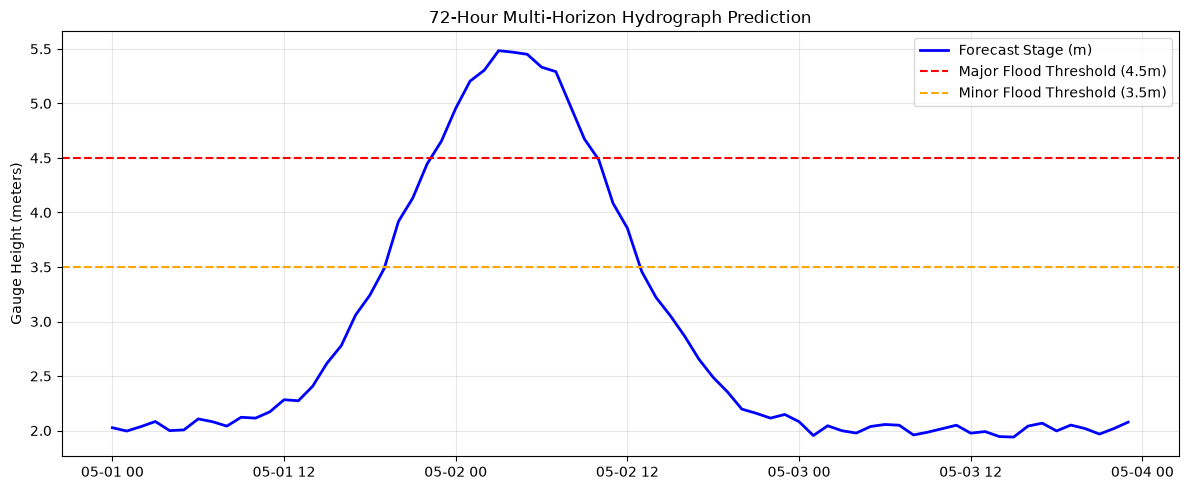

In [2]:
np.random.seed(42)
time_range = pd.date_range("2024-05-01 00:00", periods=72, freq="1h")
# Hydrograph storm peak simulation
base_level = 2.0
storm_pulse = 3.5 * np.exp(-((np.arange(72) - 28)**2) / 100.0)
gauge_levels = base_level + storm_pulse + np.random.normal(0, 0.05, 72)

df_hydro = pd.DataFrame({"timestamp": time_range, "gauge_height_m": gauge_levels})
df_hydro["rate_of_rise"] = df_hydro["gauge_height_m"].diff()

plt.figure(figsize=(12, 5))
plt.plot(df_hydro["timestamp"], df_hydro["gauge_height_m"], label="Forecast Stage (m)", color="blue", lw=2)
plt.axhline(y=4.5, color="red", linestyle="--", label="Major Flood Threshold (4.5m)")
plt.axhline(y=3.5, color="orange", linestyle="--", label="Minor Flood Threshold (3.5m)")
plt.title("72-Hour Multi-Horizon Hydrograph Prediction")
plt.ylabel("Gauge Height (meters)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()